In [1]:
print("=" * 60)
print("TRANSFORMER DEMO")
print("Religious Education Graduate Class")
print("=" * 60)

sentence = "God loves every learner."

print("\nOriginal Sentence:")
print(sentence)

TRANSFORMER DEMO
Religious Education Graduate Class

Original Sentence:
God loves every learner.


In [2]:
tokens = sentence.split()

print("Tokenization:")

for i, token in enumerate(tokens):
    print(f"Token {i + 1}: {token}")

print("\nSentence -> Tokens")
print(sentence, "->", tokens)

Tokenization:
Token 1: God
Token 2: loves
Token 3: every
Token 4: learner.

Sentence -> Tokens
God loves every learner. -> ['God', 'loves', 'every', 'learner.']


In [3]:
import numpy as np

print("=" * 60)
print("[3] WORDS BECOME VECTORS")
print("=" * 60)

clean_tokens = ["God", "loves", "every", "learner"]

embeddings = np.array([
    [1.0, 0.8, 0.2],   # God
    [0.8, 1.0, 0.3],   # loves
    [0.2, 0.4, 0.8],   # every
    [0.3, 0.5, 1.0]    # learner
])

for token, vector in zip(clean_tokens, embeddings):
    print(f"{token:10} -> {vector}")

[3] WORDS BECOME VECTORS
God        -> [1.  0.8 0.2]
loves      -> [0.8 1.  0.3]
every      -> [0.2 0.4 0.8]
learner    -> [0.3 0.5 1. ]


In [4]:
print("=" * 60)
print("[4] SELF-ATTENTION")
print("=" * 60)

# 교육용 단순화:
# 실제 Transformer에서는 학습된 가중치 행렬을 이용하여
# Query(Q), Key(K), Value(V)를 각각 만듭니다.
# 여기서는 원리를 쉽게 보기 위해 embeddings를 그대로 사용합니다.

Q = embeddings
K = embeddings
V = embeddings

# 벡터의 차원
d_k = K.shape[1]

# Query와 Key의 유사도 계산
scores = np.matmul(Q, K.T) / np.sqrt(d_k)

print("\nAttention Scores:")
print(np.round(scores, 3))

[4] SELF-ATTENTION

Attention Scores:
[[0.97  0.958 0.393 0.52 ]
 [0.958 0.999 0.462 0.6  ]
 [0.393 0.462 0.485 0.612]
 [0.52  0.6   0.612 0.774]]


In [5]:
# Softmax 함수
def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

# Attention Score를 확률 형태의 가중치로 변환
attention_weights = softmax(scores)

print("Attention Weights:")
print(np.round(attention_weights, 3))

# 각 행의 합 확인
print("\nSum of each row:")
print(np.round(np.sum(attention_weights, axis=1), 3))

Attention Weights:
[[0.314 0.31  0.176 0.2  ]
 [0.299 0.311 0.182 0.209]
 [0.227 0.243 0.248 0.282]
 [0.224 0.243 0.245 0.288]]

Sum of each row:
[1. 1. 1. 1.]


In [6]:
print("=" * 60)
print("[5] CONTEXTUAL REPRESENTATION")
print("=" * 60)

# Attention Weight와 Value를 결합
context = np.matmul(attention_weights, V)

print("\nContextual Representations:")

for token, vector in zip(clean_tokens, context):
    print(f"{token:10} -> {np.round(vector, 3)}")

[5] CONTEXTUAL REPRESENTATION

Contextual Representations:
God        -> [0.657 0.732 0.497]
loves      -> [0.646 0.727 0.507]
every      -> [0.555 0.665 0.599]
learner    -> [0.553 0.664 0.602]


[6] VISUALIZING ATTENTION


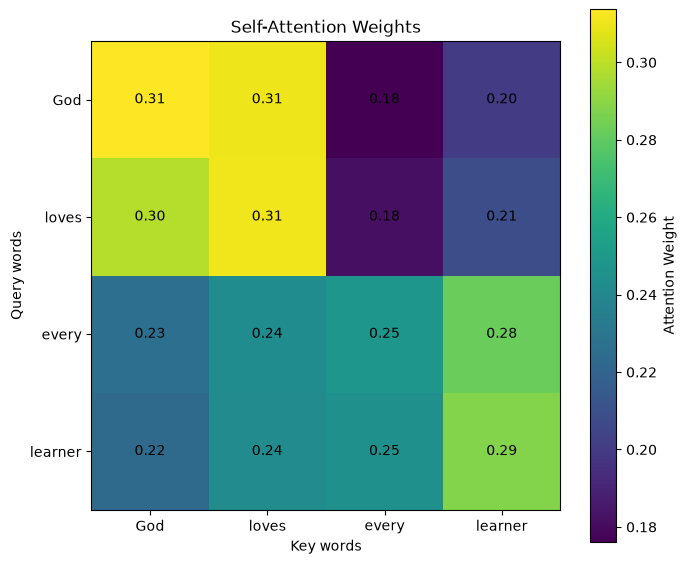

In [7]:
import matplotlib.pyplot as plt

print("=" * 60)
print("[6] VISUALIZING ATTENTION")
print("=" * 60)

plt.figure(figsize=(7, 6))

# Attention weights를 그림으로 표현
plt.imshow(attention_weights)

# 가로축과 세로축에 단어 표시
plt.xticks(
    range(len(clean_tokens)),
    clean_tokens
)

plt.yticks(
    range(len(clean_tokens)),
    clean_tokens
)

plt.xlabel("Key words")
plt.ylabel("Query words")
plt.title("Self-Attention Weights")

# 각 칸에 Attention Weight 숫자 표시
for i in range(len(clean_tokens)):
    for j in range(len(clean_tokens)):
        plt.text(
            j,
            i,
            f"{attention_weights[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.colorbar(label="Attention Weight")
plt.tight_layout()
plt.show()

In [8]:
from transformers import pipeline

print("=" * 60)
print("[7] REAL PRETRAINED TRANSFORMER")
print("=" * 60)

classifier = pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english"
)

sentences = [
    "I love studying religious education.",
    "Learning together gives me hope.",
    "I hate this class.",
    "Religious education can help people understand one another."
]

for sentence in sentences:
    result = classifier(sentence)[0]

    print("\nSentence:")
    print(sentence)

    print("Prediction:")
    print(
        f"{result['label']} "
        f"(confidence: {result['score']:.3f})"
    )

[7] REAL PRETRAINED TRANSFORMER


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Sentence:
I love studying religious education.
Prediction:
POSITIVE (confidence: 0.999)

Sentence:
Learning together gives me hope.
Prediction:
POSITIVE (confidence: 1.000)

Sentence:
I hate this class.
Prediction:
NEGATIVE (confidence: 1.000)

Sentence:
Religious education can help people understand one another.
Prediction:
POSITIVE (confidence: 0.998)
